# BLINKIT SALES ANALYSIS

In [1]:
# Importing Libraries
import pandas as pd  
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import os

In [2]:
# Loading Dataset 
folder=r"C:\Users\Dell\archive (4)"


customers = pd.read_csv(f"{folder}/blinkit_customers.csv")
orders = pd.read_csv(f"{folder}/blinkit_orders.csv")
order_items = pd.read_csv(f"{folder}/blinkit_order_items.csv")
products = pd.read_csv(f"{folder}/blinkit_products.csv")
inventory = pd.read_csv(f"{folder}/blinkit_inventory.csv")
delivery = pd.read_csv(f"{folder}/blinkit_delivery_performance.csv")
feedback = pd.read_csv(f"{folder}/blinkit_customer_feedback.csv")
marketing = pd.read_csv(f"{folder}/blinkit_marketing_performance.csv")



In [3]:
# 2. Checking Shape of All Tables
print("customers:", customers.shape)
print("orders:", orders.shape)
print("order_items:", order_items.shape)
print("products:", products.shape)
print("inventory:", inventory.shape)
print("delivery:", delivery.shape)
print("feedback:", feedback.shape)

customers: (2500, 11)
orders: (5000, 10)
order_items: (5000, 4)
products: (268, 10)
inventory: (75172, 4)
delivery: (5000, 8)
feedback: (5000, 8)


In [4]:
# Checking  All Columns Name
print("-------:CUSTOMERS:-------\n", customers.columns.tolist())
print("------:ORDERS:------\n", orders.columns.tolist())
print("------:ORDER_ITEMS:------\n", order_items.columns.tolist())
print("------:PRODUCTS:------\n", products.columns.tolist())
print("------:DELIVERY:------\n", delivery.columns.tolist())
print("------:FEEDBACK:------\n", feedback.columns.tolist())

-------:CUSTOMERS:-------
 ['customer_id', 'customer_name', 'email', 'phone', 'address', 'area', 'pincode', 'registration_date', 'customer_segment', 'total_orders', 'avg_order_value']
------:ORDERS:------
 ['order_id', 'customer_id', 'order_date', 'promised_delivery_time', 'actual_delivery_time', 'delivery_status', 'order_total', 'payment_method', 'delivery_partner_id', 'store_id']
------:ORDER_ITEMS:------
 ['order_id', 'product_id', 'quantity', 'unit_price']
------:PRODUCTS:------
 ['product_id', 'product_name', 'category', 'brand', 'price', 'mrp', 'margin_percentage', 'shelf_life_days', 'min_stock_level', 'max_stock_level']
------:DELIVERY:------
 ['order_id', 'delivery_partner_id', 'promised_time', 'actual_time', 'delivery_time_minutes', 'distance_km', 'delivery_status', 'reasons_if_delayed']
------:FEEDBACK:------
 ['feedback_id', 'order_id', 'customer_id', 'rating', 'feedback_text', 'feedback_category', 'sentiment', 'feedback_date']


In [5]:
# Cleaning All Dataset 
for df in [customers, orders, order_items, products, delivery, feedback]:
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Merging Tables And Making One Master Table 
master = order_items.merge(orders, on='order_id', how='left') \
                    .merge(products, on='product_id', how='left') \
                    .merge(customers, on='customer_id', how='left') \
                    .merge(delivery, on='order_id', how='left')

In [6]:
# checking shape  
master.shape #(rows=5000,columns=39)

(5000, 39)

In [7]:
# Checking Top 5 Rows
master.head()

,order_id,product_id,quantity,unit_price,customer_id,order_date,promised_delivery_time,actual_delivery_time,delivery_status_x,order_total,...,customer_segment,total_orders,avg_order_value,delivery_partner_id_y,promised_time,actual_time,delivery_time_minutes,distance_km,delivery_status_y,reasons_if_delayed
0,1961864118,642612,3,517.03,30065862,2024-07-17 08:34:01,2024-07-17 08:52:01,2024-07-17 08:47:01,On Time,3197.07,...,Regular,13,749.95,63230,2024-07-17 08:52:01,2024-07-17 08:47:01,-5.0,0.96,On Time,NaN
1,1549769649,378676,1,881.42,9573071,2024-05-28 13:14:29,2024-05-28 13:25:29,2024-05-28 13:27:29,On Time,976.55,...,New,5,958.06,14983,2024-05-28 13:25:29,2024-05-28 13:27:29,2.0,0.98,On Time,Traffic
2,9185164487,741341,2,923.84,45477575,2024-09-23 13:07:12,2024-09-23 13:25:12,2024-09-23 13:29:12,On Time,839.05,...,Inactive,4,327.93,39859,2024-09-23 13:25:12,2024-09-23 13:29:12,4.0,3.83,On Time,Traffic
3,9644738826,561860,1,874.78,88067569,2023-11-24 16:16:56,2023-11-24 16:34:56,2023-11-24 16:33:56,On Time,440.23,...,Premium,5,273.38,61497,2023-11-24 16:34:56,2023-11-24 16:33:56,-1.0,2.76,On Time,NaN
4,5427684290,602241,2,976.55,83298567,2023-11-20 05:00:39,2023-11-20 05:17:39,2023-11-20 05:18:39,On Time,2526.68,...,Premium,14,763.10,84315,2023-11-20 05:17:39,2023-11-20 05:18:39,1.0,2.63,On Time,Traffic


In [8]:
# Checking All Null Record
master.isna().sum()

order_id                     0
product_id                   0
quantity                     0
unit_price                   0
customer_id                  0
order_date                   0
promised_delivery_time       0
actual_delivery_time         0
delivery_status_x            0
order_total                  0
payment_method               0
delivery_partner_id_x        0
store_id                     0
product_name                 0
category                     0
brand                        0
price                        0
mrp                          0
margin_percentage            0
shelf_life_days              0
min_stock_level              0
max_stock_level              0
customer_name                0
email                        0
phone                        0
address                      0
area                         0
pincode                      0
registration_date            0
customer_segment             0
total_orders                 0
avg_order_value              0
delivery

In [9]:
# Checking Duplicate Values
print("Duplicates Rows :",master.duplicated().sum()) 

Duplicates Rows : 0


In [10]:
# Count All Negative Delivery Minutes
print("negative count:", (master['delivery_time_minutes'] < 0).sum())



negative count: 1563


In [11]:
# Convert All Negative Delivery_time_minutes Value  Into Null
master.loc[master['delivery_time_minutes'] < 0, 'delivery_time_minutes'] = np.nan

In [12]:
# Filling Null Values 
master["reasons_if_delayed"]=master["reasons_if_delayed"].fillna(master["reasons_if_delayed"].mode()[0]) 
master["delivery_time_minutes"]=master["delivery_time_minutes"].fillna(master["delivery_time_minutes"].median())

# After Filling Null values Counts
print("\nAfter filling null Values:") 
print(master.isna().sum()[master.isna().sum()>0]) 


After filling null Values:
Series([], dtype: int64)


In [13]:
# Value Counts of Order Satus and Category 
print("\n--category--") 
print(master["category"].value_counts())


--category--
category
Dairy & Breakfast        566
Household Care           509
Pet Care                 501
Fruits & Vegetables      492
Snacks & Munchies        483
Pharmacy                 481
Personal Care            454
Grocery & Staples        449
Cold Drinks & Juices     375
Instant & Frozen Food    356
Baby Care                334
Name: count, dtype: int64


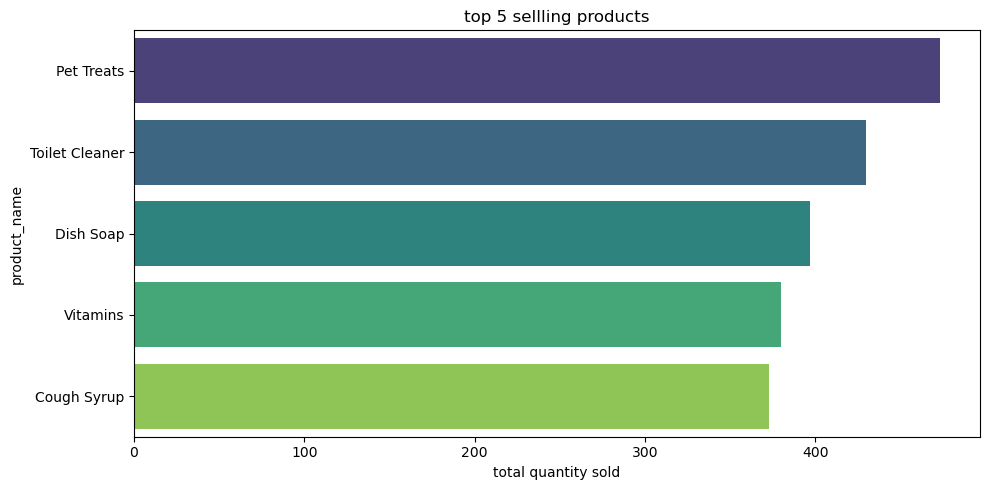

In [14]:
# BarChart top 5 products 
top_product=master.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(5) 

plt.figure(figsize=(10,5)) 
sns.barplot(x=top_product.values,y=top_product.index,hue=top_product.index,palette="viridis",legend=False)
plt.title("top 5 sellling products")
plt.xlabel("total quantity sold")
plt.tight_layout()
plt.show()


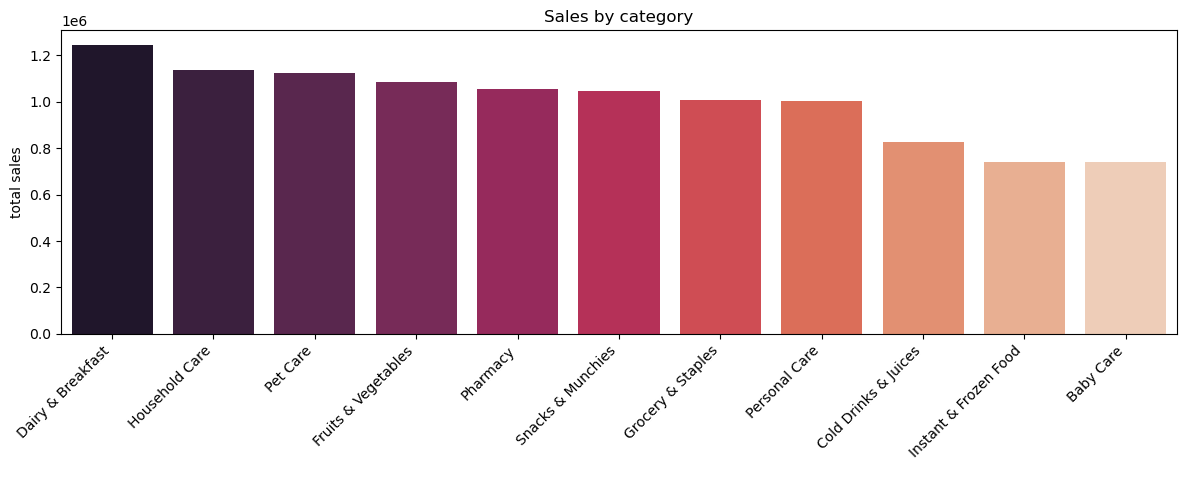

In [15]:
#  Sales By Category By Barchart
cat_sales=master.groupby("category")["order_total"].sum().sort_values(ascending=False) 
plt.figure(figsize=(12,5)) 
sns.barplot(x=cat_sales.index,y=cat_sales.values,palette="rocket",hue=cat_sales.index,legend=False) 
plt.title("Sales by category") 
plt.ylabel("total sales")  
plt.xlabel(" ")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

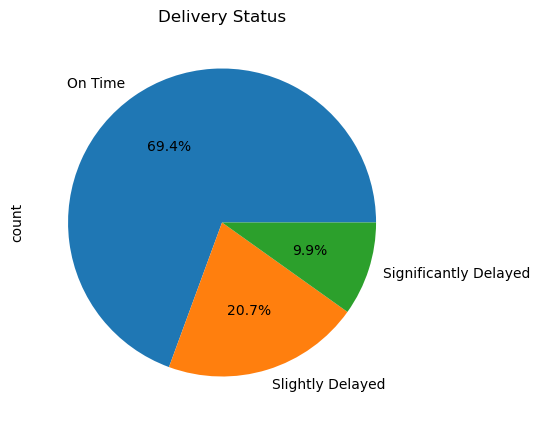

In [16]:
# 3. Delivery Status by Pie Chart
plt.figure(figsize=(15,5)) 
master['delivery_status_y'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title("Delivery Status")
plt.show()


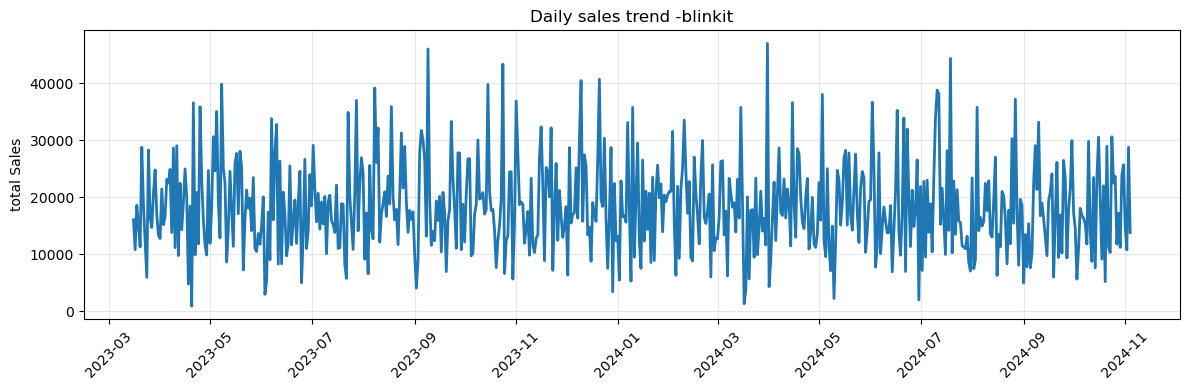

In [17]:
# Daily Sales By Linechart 
master["order_date"]=pd.to_datetime(master["order_date"]) 
daily_sales=master.groupby(master["order_date"].dt.date)["order_total"].sum() 

plt.figure(figsize=(12,4)) 
plt.plot(daily_sales.index,daily_sales.values,linewidth=2) 
plt.title("Daily sales trend -blinkit") 
plt.ylabel("total Sales") 
plt.xticks(rotation=45)
plt.grid(True,alpha=0.3) 
plt.tight_layout() 
plt.show()

In [18]:
# Total Sales and Total Orders
print("Total Sales:",master["order_total"].sum()) 
print("Total Orders:",master["order_id"].nunique())

Total Sales: 11009308.5
Total Orders: 5000


In [25]:
# Change Column Name
    
if 'delivery_status_x' in master.columns:
    master = master.rename(columns={'delivery_status_x':'delivery_status'}) 
    
if 'delivery_status_y' in master.columns:
    master = master.drop(columns=['delivery_status_y']) 
    

In [19]:
# Save Clean Dataset As Csv
master.to_csv("blinkit_clean.csv", index=False)

print(master.shape)
print(master['delivery_status'].value_counts())

Shape: (5000, 39)


In [20]:
# Saving File For SQL Only Contains Important Column 
clean_sql = master[['order_id','customer_id','order_date','product_name','category','quantity',
                    'price','order_total','delivery_status_x','delivery_time_minutes']].copy()

# Rename Column Name
clean_sql = clean_sql.rename(columns={'delivery_status_x':'delivery_status'})

# Save File As CSV For My SQL
clean_sql.to_csv("blinkit_sql_clean.csv", index=False)
print("Clean_sql Shape:", clean_sql.shape)

Clean_sql Shape: (5000, 10)
